In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load daily production data
df = pd.read_excel(
    "../data/raw/Volve production data.xlsx",
    sheet_name="Daily Production Data"
)

df.head()

,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,...,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
0,2014-04-07,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.00000,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,WI
1,2014-04-08,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
2,2014-04-09,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
3,2014-04-10,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
4,2014-04-11,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,310.37614,...,%,33.09788,10.47992,33.07195,0.0,0.0,0.0,NaN,production,OP


In [113]:
df.shape

(15634, 24)

In [114]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15634 entries, 0 to 15633
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   DATEPRD                   15634 non-null  datetime64[ns]
 1   WELL_BORE_CODE            15634 non-null  object        
 2   NPD_WELL_BORE_CODE        15634 non-null  int64         
 3   NPD_WELL_BORE_NAME        15634 non-null  object        
 4   NPD_FIELD_CODE            15634 non-null  int64         
 5   NPD_FIELD_NAME            15634 non-null  object        
 6   NPD_FACILITY_CODE         15634 non-null  int64         
 7   NPD_FACILITY_NAME         15634 non-null  object        
 8   ON_STREAM_HRS             15349 non-null  float64       
 9   AVG_DOWNHOLE_PRESSURE     8980 non-null   float64       
 10  AVG_DOWNHOLE_TEMPERATURE  8980 non-null   float64       
 11  AVG_DP_TUBING             8980 non-null   float64       
 12  AVG_ANNULUS_PRESS 

In [115]:
df.isnull().sum()

,0
DATEPRD,0
WELL_BORE_CODE,0
NPD_WELL_BORE_CODE,0
NPD_WELL_BORE_NAME,0
NPD_FIELD_CODE,0
NPD_FIELD_NAME,0
NPD_FACILITY_CODE,0
NPD_FACILITY_NAME,0
ON_STREAM_HRS,285
AVG_DOWNHOLE_PRESSURE,6654


In [116]:
# Keep only oil-producing rows
prod_df = df[
    (df["WELL_TYPE"] == "OP") &
    (df["FLOW_KIND"] == "production")
].copy()

prod_df.shape

(9143, 24)

In [117]:
df["NPD_WELL_BORE_NAME"].unique()

array(['15/9-F-1 C', '15/9-F-11', '15/9-F-12', '15/9-F-14', '15/9-F-15 D',
       '15/9-F-4', '15/9-F-5'], dtype=object)

In [118]:
df["DATEPRD"].min(), df["DATEPRD"].max()

(Timestamp('2007-09-01 00:00:00'), Timestamp('2016-12-01 00:00:00'))

In [119]:
df["WELL_TYPE"].value_counts()

,count
WELL_TYPE,
OP,9143
WI,6491


In [120]:
df["FLOW_KIND"].value_counts()

,count
FLOW_KIND,
production,9161
injection,6473


In [121]:
df.groupby("NPD_WELL_BORE_NAME")["WELL_TYPE"].unique()

,WELL_TYPE
NPD_WELL_BORE_NAME,
15/9-F-1 C,"[WI, OP]"
15/9-F-11,[OP]
15/9-F-12,[OP]
15/9-F-14,[OP]
15/9-F-15 D,[OP]
15/9-F-4,[WI]
15/9-F-5,"[WI, OP]"


## 1. Production Well Performance Analysis

In [122]:
prod_df["NPD_WELL_BORE_NAME"].unique()

array(['15/9-F-1 C', '15/9-F-11', '15/9-F-12', '15/9-F-14', '15/9-F-15 D',
       '15/9-F-5'], dtype=object)

In [123]:
well_summary = (
    prod_df.groupby("NPD_WELL_BORE_NAME")
    .agg(
        total_oil=("BORE_OIL_VOL", "sum"),
        total_gas=("BORE_GAS_VOL", "sum"),
        total_water=("BORE_WAT_VOL", "sum"),
        avg_on_stream_hours=("ON_STREAM_HRS", "mean")
    )
    .sort_values("total_oil", ascending=False)
)

well_summary

,total_oil,total_gas,total_water,avg_on_stream_hours
NPD_WELL_BORE_NAME,,,,
15/9-F-12,4579609.55,6.675423e+08,6833320.37,21.336410
15/9-F-14,3942233.39,5.780095e+08,7121249.74,20.541124
15/9-F-11,1147849.10,1.743105e+08,1090806.27,22.322932
15/9-F-1 C,177187.33,2.636307e+07,207147.92,13.386469
15/9-F-15 D,148518.56,2.250535e+07,52366.40,18.225800
15/9-F-5,38432.80,6.131674e+06,12788.60,19.981424


- which well produced the most oil ? 15/9-F-12
- which produced the most gas ? 15/9-F-12
- which produced the most water? 15/9-F-14
- which had lower average operating hours? 15/9-F-1 C

In [124]:
prod_df["UPTIME_PCT"] = (
    prod_df["ON_STREAM_HRS"] / 24 * 100
).clip(upper=100)

In [125]:
prod_df.loc[
    prod_df["BORE_WAT_VOL"] < 0,
    "BORE_WAT_VOL"
] = np.nan

In [126]:
prod_df["WATER_CUT_PCT"] = (
    prod_df["BORE_WAT_VOL"] /
    (prod_df["BORE_OIL_VOL"] + prod_df["BORE_WAT_VOL"])
) * 100

In [127]:
prod_df["OIL_RATE_24H"] = np.where(
    prod_df["ON_STREAM_HRS"] > 0,
    prod_df["BORE_OIL_VOL"] / prod_df["ON_STREAM_HRS"] * 24,
    np.nan
)

In [128]:
prod_df["GAS_RATE_24H"] = np.where(
    prod_df["ON_STREAM_HRS"] > 0,
    prod_df["BORE_GAS_VOL"] / prod_df["ON_STREAM_HRS"] * 24,
    np.nan
)

In [129]:
kpi_summary = (
    prod_df.groupby("NPD_WELL_BORE_NAME")
    .agg(
        avg_uptime_pct=("UPTIME_PCT", "mean"),
        avg_water_cut_pct=("WATER_CUT_PCT", "mean"),
        avg_oil_rate_24h=("OIL_RATE_24H", "mean"),
        avg_gas_rate_24h=("GAS_RATE_24H", "mean")

    )
    .round(2)
)

kpi_summary

,avg_uptime_pct,avg_water_cut_pct,avg_oil_rate_24h,avg_gas_rate_24h
NPD_WELL_BORE_NAME,,,,
15/9-F-1 C,55.77,51.07,415.01,61785.72
15/9-F-11,93.01,38.28,1050.71,159875.57
15/9-F-12,88.90,59.58,1678.14,244325.96
15/9-F-14,85.58,65.12,1508.49,220710.76
15/9-F-15 D,75.94,19.31,200.77,30529.91
15/9-F-5,83.26,24.54,319.10,50916.33


### KPI Interpretation:
- 15/9-F-12 is the strongest well overall. It has the highest average oil rate at approximately 1,678 units/day, the second-highest uptime, and the highest total gas production. This makes it the strongest overall producer in both oil and gas, although its water cut is also relatively high.
- 15/9-F-14 is also a major producer, with an average oil rate of approximately 1,508 units/day, the third-highest uptime, and the second-highest total gas production. However, its average water cut is about 65%, meaning a large portion of the produced liquid is water rather than oil.
- 15/9-F-11 is the most operationally consistent producing well, with the highest average uptime at approximately 93%. It also has strong oil production and is the third-highest gas-producing well, making it a reliable and balanced producer.
- 15/9-F-1 C has the lowest uptime, operating for only a little over half of the available daily time on average. Its water cut is also above 50%, and both its oil and gas production are much lower than the top-performing wells.
- 15/9-F-15 D has the lowest water cut, but it also has the lowest average oil production rate and relatively low gas production. This shows that low water cut does not necessarily mean strong overall production performance.
- 15/9-F-5 has decent uptime and relatively low water cut, but both its oil and gas production remain low, suggesting limited production capacity compared with the stronger wells.
#Main Takeaway
F-12 and F-14 dominate both oil and gas production, F-11 is the most operationally reliable, while F-1 C, F-15 D, and F-5 show weaker overall production performance for different reasons.

## 2. Monthly Production Trend Analysis

In [130]:
prod_df["MONTH"] = (
    prod_df["DATEPRD"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

In [131]:
monthly_prod = (
    prod_df.groupby(
        ["MONTH", "NPD_WELL_BORE_NAME"],
        as_index=False
    )
    .agg(
        oil_volume=("BORE_OIL_VOL", "sum"),
        gas_volume=("BORE_GAS_VOL", "sum"),
        water_volume=("BORE_WAT_VOL", "sum"),
        avg_uptime_pct=("UPTIME_PCT", "mean")
    )
)

monthly_prod.head()

,MONTH,NPD_WELL_BORE_NAME,oil_volume,gas_volume,water_volume,avg_uptime_pct
0,2008-02-01,15/9-F-12,49091.06,7068009.29,412.61,94.126155
1,2008-02-01,15/9-F-14,0.00,0.00,0.00,0.000000
2,2008-03-01,15/9-F-12,83361.26,12191170.91,27.42,88.052196
3,2008-03-01,15/9-F-14,0.00,0.00,0.00,0.000000
4,2008-04-01,15/9-F-12,74532.45,11506440.74,496.24,88.167624


In [132]:
monthly_prod["WATER_CUT_PCT"] = (
    monthly_prod["water_volume"] /
    (
        monthly_prod["oil_volume"]
        + monthly_prod["water_volume"]
    )
) * 100

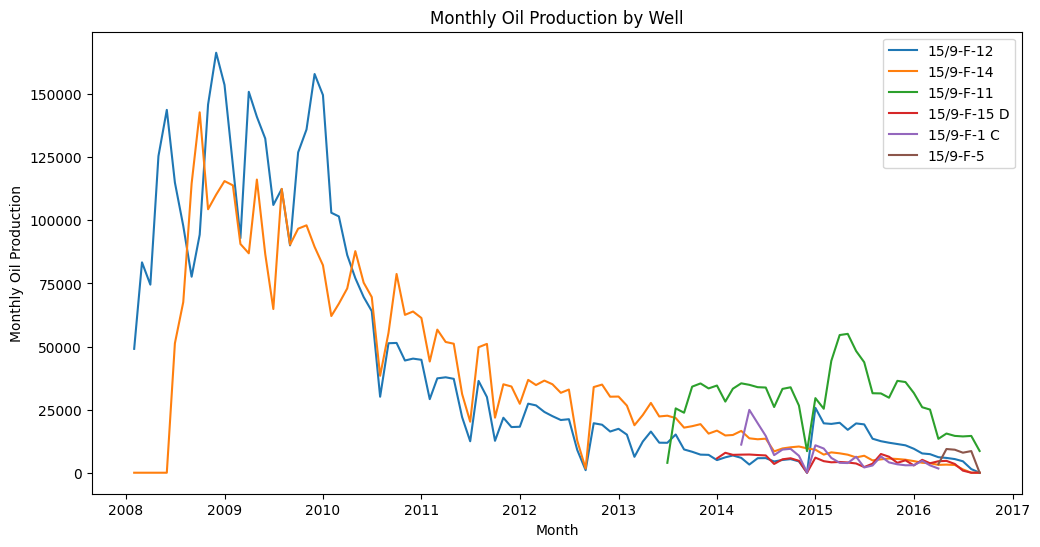

In [133]:
plt.figure(figsize=(12, 6))

for well in monthly_prod["NPD_WELL_BORE_NAME"].unique():
    well_data = monthly_prod[
        monthly_prod["NPD_WELL_BORE_NAME"] == well
    ]

    plt.plot(
        well_data["MONTH"],
        well_data["oil_volume"],
        label=well
    )

plt.xlabel("Month")
plt.ylabel("Monthly Oil Production")
plt.title("Monthly Oil Production by Well")
plt.legend()
plt.show()

### Monthly Oil Production Trend Interpretation

- **15/9-F-12** was the strongest early-life producer, reaching the highest monthly oil production in the field before experiencing a substantial long-term decline.
- **15/9-F-14** also showed strong early production, but gradually declined throughout the field life.
- **15/9-F-11** became a more significant producer later in the field life and maintained relatively stable production before declining near the end of operations.
- **15/9-F-15 D** remained a consistently low-rate producer rather than declining from a high initial production level.
- **15/9-F-1 C** experienced a short period of increased production around 2014, followed by a rapid decline and lower sustained output.
- **15/9-F-5** remained one of the lowest-producing wells throughout its operating period.
- Overall, field production shifted from being dominated by **F-12 and F-14 in the early years** toward greater contribution from **F-11 later in the field life**.

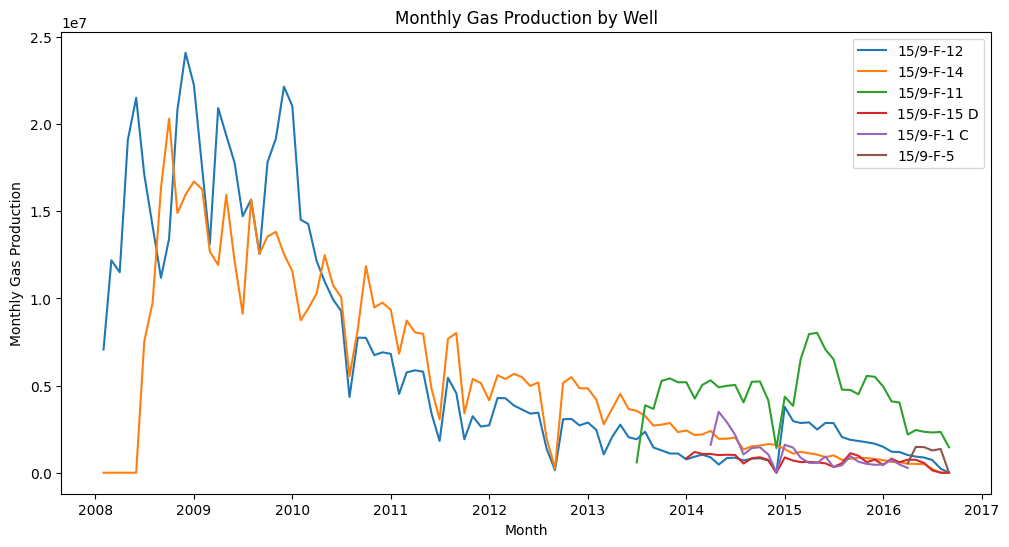

In [134]:
plt.figure(figsize=(12, 6))

for well in monthly_prod["NPD_WELL_BORE_NAME"].unique():
    well_data = monthly_prod[
        monthly_prod["NPD_WELL_BORE_NAME"] == well
    ]

    plt.plot(
        well_data["MONTH"],
        well_data["gas_volume"],
        label=well
    )

plt.xlabel("Month")
plt.ylabel("Monthly Gas Production")
plt.title("Monthly Gas Production by Well")
plt.legend()
plt.show()

#### Interpretation

- F-12 was the strongest early-life gas producer, reaching the highest monthly gas production before experiencing a substantial long-term decline.
- F-14 also showed strong early gas production followed by a gradual decline over time.
- F-11 became a more significant gas producer later in the field life and briefly became the leading contributor as F-12 and F-14 declined.
- F-1 C showed a short-lived increase in gas production around 2014 before declining.
- F-15 D and F-5 remained relatively low gas producers throughout their operating periods.
- Overall, gas production shifted from early dominance by F-12 and F-14 toward greater contribution from F-11 later in the field life.

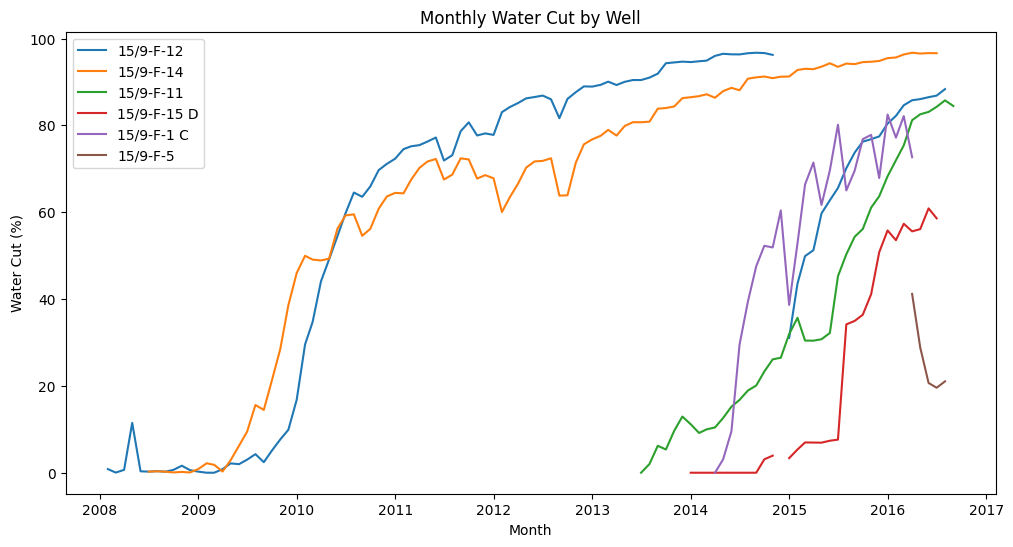

In [135]:
plt.figure(figsize=(12, 6))

for well in monthly_prod["NPD_WELL_BORE_NAME"].unique():
    well_data = monthly_prod[
        monthly_prod["NPD_WELL_BORE_NAME"] == well
    ]

    plt.plot(
        well_data["MONTH"],
        well_data["WATER_CUT_PCT"],
        label=well
    )

plt.xlabel("Month")
plt.ylabel("Water Cut (%)")
plt.title("Monthly Water Cut by Well")
plt.legend()
plt.show()

#### Interpretation

- F-12 and F-14 began with relatively low water cut but experienced substantial increases over time, eventually reaching water cuts above 90%.
- The increase in water cut occurred alongside the long-term decline in oil production for both major early-life producers.
- F-11 initially had low water cut after coming online later in the field life, but water cut increased steadily and exceeded 80% toward the end of the period.
- F-1 C showed a rapid and highly variable increase in water cut, while F-15 D maintained relatively low water cut early before increasing later in its producing life.
- Overall, several wells became increasingly water-dominated as the field matured, meaning a greater proportion of produced liquid consisted of water rather than oil.

## 3. Water Injection Performance Analysis

In [136]:
# Keep only water-injection records
inj_df = df[
    (df["WELL_TYPE"] == "WI") &
    (df["FLOW_KIND"] == "injection")
].copy()

inj_df.shape

(6473, 24)

In [137]:
inj_df["NPD_WELL_BORE_NAME"].unique()

array(['15/9-F-4', '15/9-F-5'], dtype=object)

In [138]:
inj_df["UPTIME_PCT"] = (
    inj_df["ON_STREAM_HRS"] / 24
) * 100

In [139]:
inj_df["INJECTION_RATE_24H"] = np.where(
    inj_df["ON_STREAM_HRS"] > 0,
    inj_df["BORE_WI_VOL"] / inj_df["ON_STREAM_HRS"] * 24,
    np.nan
)

In [140]:
injection_summary = (
    inj_df.groupby("NPD_WELL_BORE_NAME")
    .agg(
        total_water_injected=("BORE_WI_VOL", "sum"),
        avg_uptime_pct=("UPTIME_PCT", "mean"),
        avg_injection_rate_24h=("INJECTION_RATE_24H", "mean")
    )
    .sort_values("total_water_injected", ascending=False)
    .round(2)
)

injection_summary

,total_water_injected,avg_uptime_pct,avg_injection_rate_24h
NPD_WELL_BORE_NAME,,,
15/9-F-4,16240727.04,84.34,6044.59
15/9-F-5,14089406.49,80.01,5840.91


In [141]:
injector_availability = (
    inj_df.groupby("NPD_WELL_BORE_NAME")
    .agg(
        zero_injection_days=(
            "BORE_WI_VOL",
            lambda x: (x == 0).sum()
        ),
        zero_onstream_days=(
            "ON_STREAM_HRS",
            lambda x: (x == 0).sum()
        )
    )
)

injector_availability

,zero_injection_days,zero_onstream_days
NPD_WELL_BORE_NAME,,
15/9-F-4,144,345
15/9-F-5,143,466


In [142]:
inj_df["MONTH"] = (
    inj_df["DATEPRD"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_injection = (
    inj_df.groupby(
        ["MONTH", "NPD_WELL_BORE_NAME"],
        as_index=False
    )
    .agg(
        water_injected=("BORE_WI_VOL", "sum"),
        avg_uptime_pct=("UPTIME_PCT", "mean")
    )
)

monthly_injection.head()

,MONTH,NPD_WELL_BORE_NAME,water_injected,avg_uptime_pct
0,2007-09-01,15/9-F-4,0.0,NaN
1,2007-09-01,15/9-F-5,0.0,NaN
2,2007-10-01,15/9-F-4,0.0,NaN
3,2007-10-01,15/9-F-5,0.0,NaN
4,2007-11-01,15/9-F-4,0.0,NaN


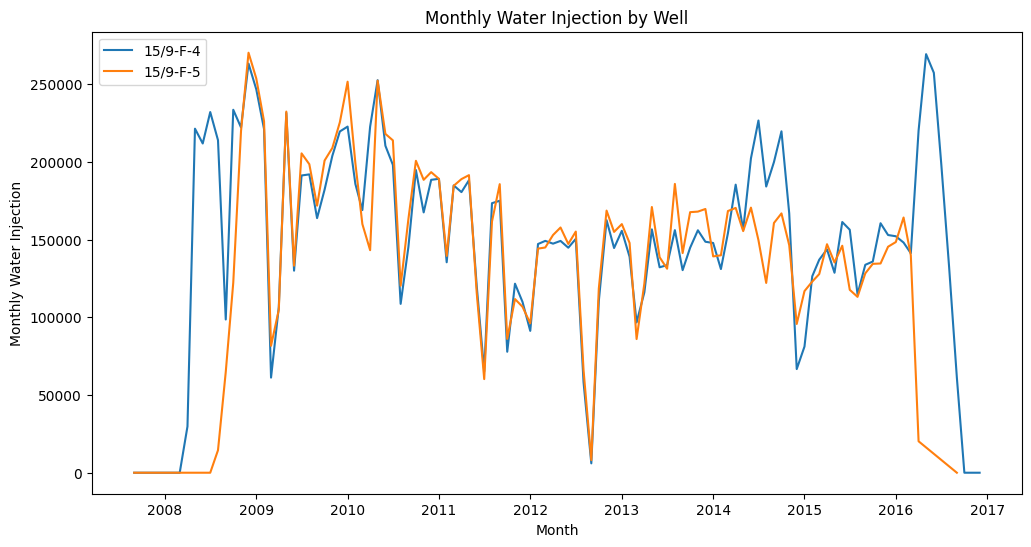

In [143]:
plt.figure(figsize=(12, 6))

for well in monthly_injection["NPD_WELL_BORE_NAME"].unique():
    well_data = monthly_injection[
        monthly_injection["NPD_WELL_BORE_NAME"] == well
    ]

    plt.plot(
        well_data["MONTH"],
        well_data["water_injected"],
        label=well
    )

plt.xlabel("Month")
plt.ylabel("Monthly Water Injection")
plt.title("Monthly Water Injection by Well")
plt.legend()
plt.show()

### Water Injection Performance Interpretation

- **15/9-F-4** is the stronger injection well overall. It injected approximately **16.24 million units of water**, had an average uptime of about **84.3%**, and achieved the highest normalized injection rate at approximately **6,045 units/day**.

- **15/9-F-5** also provided substantial reservoir support, injecting approximately **14.09 million units of water**. However, its average uptime was lower at about **80.0%**, and its normalized injection rate was slightly lower at approximately **5,841 units/day**.

- **15/9-F-4 operated more consistently** than F-5, with fewer zero on-stream days (**345 vs. 466**).

- Overall, **F-4 appears to be the more reliable and higher-performing injector**, while F-5 still contributes significant injection support but experiences more inactive periods.

## 4. Production vs. Water Injection Relationship

In [144]:
monthly_field_prod = (
    monthly_prod.groupby("MONTH", as_index=False)
    .agg(
        total_oil=("oil_volume", "sum"),
        total_gas=("gas_volume", "sum"),
        total_water=("water_volume", "sum")
    )
)

monthly_field_prod.head()

,MONTH,total_oil,total_gas,total_water
0,2008-02-01,49091.06,7068009.29,412.61
1,2008-03-01,83361.26,12191170.91,27.42
2,2008-04-01,74532.45,11506440.74,496.24
3,2008-05-01,125478.56,19091871.52,16280.12
4,2008-06-01,143786.85,21512333.93,474.37


In [145]:
monthly_field_inj = (
    monthly_injection.groupby("MONTH", as_index=False)
    .agg(
        total_water_injected=("water_injected", "sum")
    )
)

monthly_field_inj.head()

,MONTH,total_water_injected
0,2007-09-01,0.0
1,2007-10-01,0.0
2,2007-11-01,0.0
3,2007-12-01,0.0
4,2008-01-01,0.0


In [146]:
prod_inj = pd.merge(
    monthly_field_prod,
    monthly_field_inj,
    on="MONTH",
    how="inner"
)

prod_inj.head()

,MONTH,total_oil,total_gas,total_water,total_water_injected
0,2008-02-01,49091.06,7068009.29,412.61,0.000000
1,2008-03-01,83361.26,12191170.91,27.42,0.000000
2,2008-04-01,74532.45,11506440.74,496.24,29752.686893
3,2008-05-01,125478.56,19091871.52,16280.12,221337.106474
4,2008-06-01,143786.85,21512333.93,474.37,211803.653864


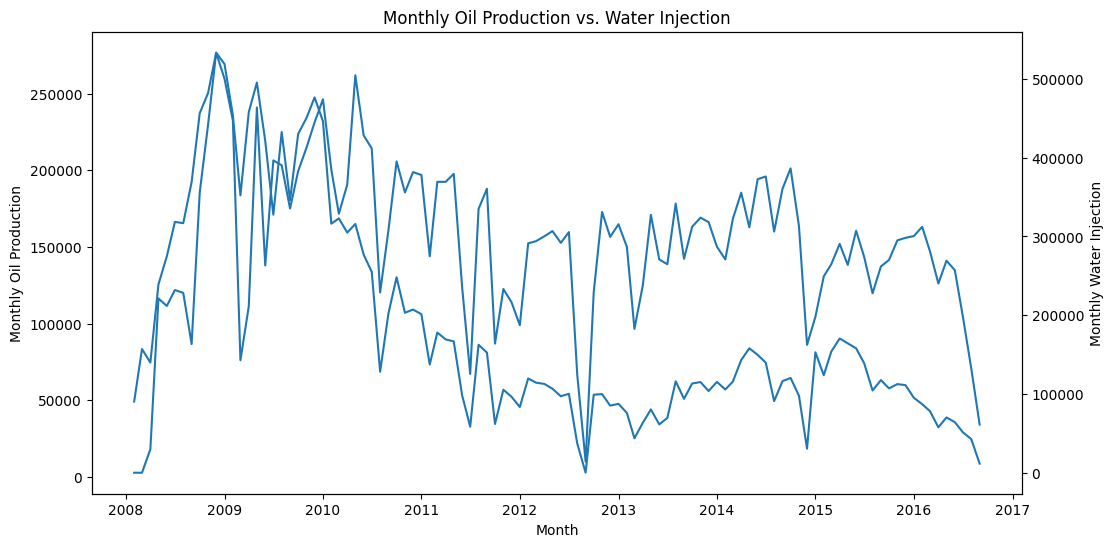

In [147]:
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    prod_inj["MONTH"],
    prod_inj["total_oil"],
    label="Oil Production"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Monthly Oil Production")

ax2 = ax1.twinx()

ax2.plot(
    prod_inj["MONTH"],
    prod_inj["total_water_injected"],
    label="Water Injection"
)

ax2.set_ylabel("Monthly Water Injection")

plt.title("Monthly Oil Production vs. Water Injection")
plt.show()

In [148]:
correlation = prod_inj[
    ["total_oil", "total_water_injected"]
].corr()

correlation

,total_oil,total_water_injected
total_oil,1.000000,0.546538
total_water_injected,0.546538,1.000000


In [149]:
prod_inj["oil_next_month"] = (
    prod_inj["total_oil"].shift(-1)
)

lag_1_corr = prod_inj[
    ["total_water_injected", "oil_next_month"]
].corr()

lag_1_corr

,total_water_injected,oil_next_month
total_water_injected,1.000000,0.351286
oil_next_month,0.351286,1.000000


In [150]:
prod_inj["oil_3_months_later"] = (
    prod_inj["total_oil"].shift(-3)
)

lag_3_corr = prod_inj[
    ["total_water_injected", "oil_3_months_later"]
].corr()

lag_3_corr

,total_water_injected,oil_3_months_later
total_water_injected,1.000000,0.184797
oil_3_months_later,0.184797,1.000000


In [151]:
prod_df[prod_df["BORE_WAT_VOL"] < 0][
    [
        "DATEPRD",
        "NPD_WELL_BORE_NAME",
        "BORE_OIL_VOL",
        "BORE_WAT_VOL"
    ]
]

,DATEPRD,NPD_WELL_BORE_NAME,BORE_OIL_VOL,BORE_WAT_VOL


### Production vs. Injection Interpretation

- Monthly oil production and water injection showed a moderate positive same-month correlation of approximately **0.55**.
- The relationship weakened to approximately **0.35** at a one-month lag and **0.18** at a three-month lag.
- This suggests that oil production and water injection tended to move together most strongly during the same operating periods.
- The relationship should be interpreted as association rather than causation, since production may also be influenced by reservoir conditions, well availability, field maturity, and operational decisions.